# Bongkar Isi Foto: Metadata dan Angka Representasi Gambar

0. Import library dan tentukan file

In [27]:
import os                      # os: berinteraksi dengan sistem file (cek ukuran file)
import hashlib                 # hashlib: membuat sidik jari (hash) file
import numpy as np             # numpy: mengolah gambar sebagai array angka
import matplotlib.pyplot as plt  # matplotlib: menampilkan gambar dan grafik
from PIL import Image, ImageFilter          # PIL (Pillow): membuka dan memproses gambar
from PIL.ExifTags import TAGS, GPSTAGS      # kamus: kode angka EXIF -> nama tag yang terbaca manusia

PATH = "foto3.jpg"             # nama file foto (harus satu folder dengan notebook)

1. Tampilkan foto

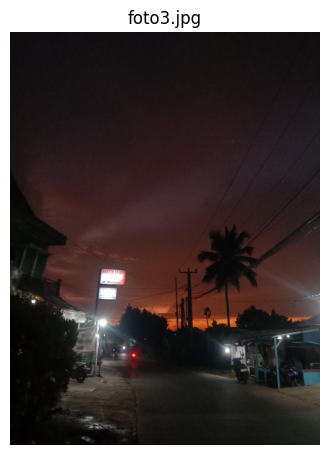

In [28]:
img = Image.open(PATH)          # buka file gambar; hasilnya objek Image (belum dibaca penuh)
plt.figure(figsize=(4, 7))     # buat kanvas ukuran 4x7 inci (portrait)
plt.imshow(img)                # gambar foto ke kanvas
plt.axis("off")                # sembunyikan sumbu x dan y
plt.title("foto3.jpg")         # judul gambar
plt.show()                     # tampilkan

2. Info file

File di komputer pada dasarnya hanya deretan **byte**. Dari byte-byte itu kita bisa mengambil ukuran, sidik jari (hash), dan tipe aslinya.

In [29]:
ukuran = os.path.getsize(PATH)           # ukuran file dalam byte
print("Ukuran file :", ukuran, "byte =", round(ukuran / 1024, 1), "KB")

with open(PATH, "rb") as f:              # buka file mode 'rb' = read binary (baca byte mentah)
    data = f.read()                      # baca seluruh isi file ke variabel data

print("SHA-256     :", hashlib.sha256(data).hexdigest())
# SHA-256 = sidik jari unik file. Satu piksel berubah saja, hash-nya ikut berubah total.

print("Magic bytes :", data[:4].hex())
# 4 byte pertama file. FFD8FFE0 = tanda khas JPEG, jadi tipe file tidak bisa dipalsukan hanya dengan ganti ekstensi.

Ukuran file : 3589467 byte = 3505.3 KB
SHA-256     : ed77e464141752422e9927e8bf7779ff5bfc742afd01680fb7582c0212013438
Magic bytes : ffd8ffe1


3. Metadata
Ada dua sumber utama:
- Properti dasar: format, ukuran, mode warna
- EXIF: data kamera, waktu, lokasi GPS (kalau ada)

In [30]:
print("Format :", img.format)                  # jenis file (JPEG, PNG, dll)
print("Ukuran :", img.size, "(lebar x tinggi)")   # dalam piksel
print("Mode   :", img.mode)                      # RGB = 3 channel warna (Red, Green, Blue)

for k, v in img.info.items():                    # img.info = data tambahan bawaan file (JFIF, ICC profile, dll)
    if k == "icc_profile":
        v = f"{len(v)} byte"                     # ICC profile panjang, jadi tampilkan ukurannya saja
    print("Info   :", k, "=", v)

Format : JPEG
Ukuran : (3120, 4160) (lebar x tinggi)
Mode   : RGB
Info   : exif = b'Exif\x00\x00II*\x00\x08\x00\x00\x00\x0e\x00\x0f\x01\x02\x00 \x00\x00\x00\xb6\x00\x00\x00\x01\x01\x04\x00\x01\x00\x00\x00@\x10\x00\x00\x12\x01\x03\x00\x01\x00\x00\x00\x00\x00\x00\x002\x01\x02\x00\x14\x00\x00\x00\xd6\x00\x00\x00%\x88\x04\x00\x01\x00\x00\x00\'\x04\x00\x00\x1b\x01\x05\x00\x01\x00\x00\x00\xea\x00\x00\x00\x1a\x01\x05\x00\x01\x00\x00\x00\xf2\x00\x00\x00\x00\x01\x04\x00\x01\x00\x00\x000\x0c\x00\x00\x10\x01\x02\x00 \x00\x00\x00\xfa\x00\x00\x001\x01\x02\x00 \x00\x00\x00\x1a\x01\x00\x00\x0e\x01\x02\x00 \x00\x00\x00:\x01\x00\x00\x13\x02\x03\x00\x01\x00\x00\x00\x02\x00\x00\x00i\x87\x04\x00\x01\x00\x00\x00Z\x01\x00\x00(\x01\x03\x00\x01\x00\x00\x00\x02\x00\x00\x00R\x05\x00\x00vivo\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x002025:05:19 18:07:02\x00H\x00\x00\x00\x01\x00\x00\x00H\x00\x00\x00\x01\x00\x00\x00V2026\x00\x00\x00\x00\x00\x00\x0

In [31]:
exif = img.getexif()                              # ambil blok EXIF (kalau ada)
print("Jumlah tag EXIF:", len(exif))

for tag_id, val in exif.items():                  # tiap tag berupa pasangan (kode angka, nilai)
    print(TAGS.get(tag_id, tag_id), ":", val)     # terjemahkan kode ke nama (misal 271 -> Make)

gps = exif.get_ifd(0x8825)                        # 0x8825 = alamat blok GPS dalam standar EXIF
for tag_id, val in gps.items():
    print("GPS", GPSTAGS.get(tag_id, tag_id), ":", val)

if len(exif) == 0:
    print("EXIF kosong: kemungkinan sudah dihapus WhatsApp/sosmed atau terkompresi saat upload.")

Jumlah tag EXIF: 14
ImageWidth : 3120
ImageLength : 4160
GPSInfo : 1063
ResolutionUnit : 2
ExifOffset : 346
ImageDescription :                                
Make : vivo                           
Model : V2026                          
Software : MediaTek Camera Application    
Orientation : 0
DateTime : 2025:05:19 18:07:02
YCbCrPositioning : 2
XResolution : 72.0
YResolution : 72.0
GPS GPSVersionID : b'\x02\x02\x00\x00'
GPS GPSLatitudeRef : S
GPS GPSLatitude : (6.0, 29.0, 17.4726)
GPS GPSLongitudeRef : E
GPS GPSLongitude : (106.0, 43.0, 43.0133)
GPS GPSAltitudeRef : b'\x00'
GPS GPSAltitude : 144.0
GPS GPSTimeStamp : (11.0, 6.0, 59.0)
GPS GPSProcessingMethod : b'ASCII\x00\x00\x00GPS\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00'
GPS GPSDateStamp : 2025:05:19


4. Gambar menjadi angka

Foto = matriks 3 dimensi: `(tinggi, lebar, channel)`. Setiap piksel punya 3 angka (R, G, B) dengan rentang 0 sampai 255.

In [32]:
arr = np.array(img)                       # ubah gambar jadi array numpy
print("Shape        :", arr.shape)      # (tinggi, lebar, 3)
print("Tipe data    :", arr.dtype)      # uint8 = bilangan bulat 0-255 (8 bit)
print("Total piksel :", arr.shape[0] * arr.shape[1])
print("Total angka  :", arr.size)       # piksel x 3 channel
print("Piksel [0,0] (pojok kiri atas):", arr[0, 0])
tengah = arr[arr.shape[0] // 2, arr.shape[1] // 2]   # // = pembagian bulat
print("Piksel tengah:", tengah)

Shape        : (4160, 3120, 3)
Tipe data    : uint8
Total piksel : 12979200
Total angka  : 38937600
Piksel [0,0] (pojok kiri atas): [18 14 15]
Piksel tengah: [63 34 30]


5. Statistik per channel

In [33]:
for i, nama in enumerate(["R", "G", "B"]):     # i = 0,1,2 ; nama = huruf channel
    c = arr[:, :, i]                              # ambil satu channel saja (semua baris, semua kolom)
    print(f"{nama}: min={c.min()}  max={c.max()}  mean={c.mean():.2f}  "
          f"median={np.median(c):.0f}  std={c.std():.2f}")
# min/max = terendah/tertinggi, mean = rata-rata, median = nilai tengah,
# std = standar deviasi (seberapa menyebar nilainya)

R: min=0  max=255  mean=43.10  median=34  std=33.14
G: min=0  max=255  mean=31.86  median=25  std=26.37
B: min=0  max=255  mean=30.94  median=26  std=25.76


In [34]:
gray = np.array(img.convert("L"))           # "L" = grayscale: 1 angka per piksel (0 hitam, 255 putih)

print(f"Kecerahan rata-rata: {gray.mean():.2f} / 255 = {gray.mean() / 255 * 100:.1f}%")
print("Piksel gelap  (<50) :", f"{(gray < 50).mean() * 100:.1f}%")
print("Piksel terang (>200):", f"{(gray > 200).mean() * 100:.1f}%")
# (gray < 50) menghasilkan array True/False; .mean() dari True/False = proporsi True

Kecerahan rata-rata: 35.13 / 255 = 13.8%
Piksel gelap  (<50) : 80.1%
Piksel terang (>200): 0.4%


6. Histogram

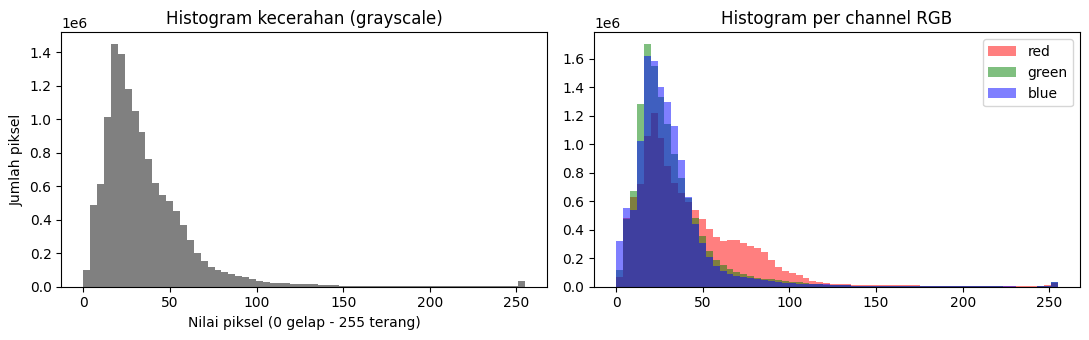

In [35]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))

ax[0].hist(gray.ravel(), bins=64, range=(0, 255), color="gray")   # ravel() = ratakan array 2D jadi 1D
ax[0].set_title("Histogram kecerahan (grayscale)")
ax[0].set_xlabel("Nilai piksel (0 gelap - 255 terang)")
ax[0].set_ylabel("Jumlah piksel")

for i, warna in enumerate(["red", "green", "blue"]):               # satu garis per channel
    ax[1].hist(arr[:, :, i].ravel(), bins=64, range=(0, 255), color=warna, alpha=0.5, label=warna)
ax[1].set_title("Histogram per channel RGB")
ax[1].legend()

plt.tight_layout()
plt.show()
# Grafik menumpuk di kiri = foto gelap (malam). Bukit kecil di kanan = area terang (baju putih, lampu).

In [36]:
hist, _ = np.histogram(gray, bins=8, range=(0, 256))   # bagi 0-255 jadi 8 kelompok
for i, h in enumerate(hist):
    persen = h / gray.size * 100
    print(f"{i*32:3d}-{i*32+31:3d} | {persen:5.1f}% {'#' * int(persen / 2)}")

  0- 31 |  56.1% ############################
 32- 63 |  34.4% #################
 64- 95 |   6.6% ###
 96-127 |   1.6% 
128-159 |   0.6% 
160-191 |   0.3% 
192-223 |   0.1% 
224-255 |   0.4% 


7. Warna dominan

(29, 21, 22) 27.8%
(44, 30, 31) 22.7%
(14, 13, 12) 22.6%
(68, 41, 37) 18.8%
(94, 78, 73) 8.2%


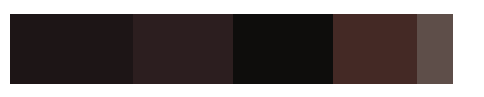

In [37]:
kecil = img.resize((100, 100)).quantize(colors=5).convert("RGB")
# resize: perkecil supaya cepat | quantize(5): sederhanakan semua warna menjadi 5 warna

warna, jumlah = np.unique(np.array(kecil).reshape(-1, 3), axis=0, return_counts=True)
# reshape(-1,3): jadikan daftar piksel | unique: cari warna berbeda + hitung kemunculannya

urut = np.argsort(-jumlah)                 # urutan indeks dari yang paling banyak muncul
fig, ax = plt.subplots(figsize=(6, 1))
for i, idx in enumerate(urut):
    rgb = tuple(int(x) for x in warna[idx])
    persen = jumlah[idx] / jumlah.sum() * 100
    print(rgb, f"{persen:.1f}%")
    ax.barh(0, persen, left=sum(jumlah[urut[:i]]) / jumlah.sum() * 100, color=np.array(rgb) / 255)
ax.axis("off")
plt.show()

8. Kecerahan per zona dan estimasi noise

In [38]:
h = arr.shape[0]                                  # tinggi gambar
zona = [("Atas (0-50%)", 0, h // 2),
        ("Tengah (50-75%)", h // 2, h * 3 // 4),
        ("Bawah (75-100%)", h * 3 // 4, h)]
for nama, a, b in zona:
    print(f"{nama:18s}: {gray[a:b].mean():.2f}")   # rata-rata kecerahan tiap potongan horizontal

Atas (0-50%)      : 28.12
Tengah (50-75%)   : 51.98
Bawah (75-100%)   : 32.29


In [39]:
blur = np.array(img.convert("L").filter(ImageFilter.GaussianBlur(2)))   # versi buram
noise = np.abs(gray.astype(int) - blur).std()
# astype(int) penting: uint8 tidak bisa negatif, jadi hasil pengurangan bisa 'melompat' (overflow)
print("Estimasi noise:", round(float(noise), 2))
# Semakin besar selisih asli vs buram, semakin banyak butiran/noise (ciri foto malam ISO tinggi).

Estimasi noise: 2.76
